# Task 4 — GPU Follow-up: ResNet, EfficientNet, ConvNeXt

Notebook นี้รันเดี่ยวบน Colab/Kaggle GPU ได้: มี source helpers ฝังไว้ ดาวน์โหลดข้อมูลจากลิงก์เพื่อน ตรวจภาพซ้ำ ฝึกแบบ grouped OOF เทียบ single-view/TTA/soft ensembles และสร้างคำทำนายหลังเลือกโมเดล

**วิธีใช้:** เลือก GPU runtime และเปิด Internet → ตั้งค่าด้านล่างก่อนรัน → Run all. บน Colab เลือกใช้ Google Drive เพื่อเก็บ checkpoints ข้าม session. `full` มี 5 recipes × 5 folds = 25 fits/395 training epochs ยังไม่รวม full-data refit; ใช้หลายชั่วโมง. `balanced` มี baseline/ResNet cosine/EfficientNet × 3 folds สำหรับรอบเบื้องต้น. เปลี่ยน configuration หลังเริ่มแล้วให้เปลี่ยน RUN_NAME ด้วย

ยังไม่มีคะแนนทดลองใหม่ในไฟล์นี้: local tests เป็นเพียง smoke checks. ผลเดิมเพื่อน 0.95447 ใช้ epoch selection/folds ต่างจากการตรวจครั้งนี้ จึงเปรียบเทียบตรง ๆ ไม่ได้ ต้องใช้ paired baseline ที่ฝึกใน notebook นี้

## 1. Runtime & Configuration

In [1]:
from pathlib import Path
import sys, os, json, hashlib, importlib.util, subprocess
# Keep Colab/Kaggle's compatible CUDA torch/torchvision pair.
required = {"numpy":"numpy", "pandas":"pandas", "PIL":"pillow", "scipy":"scipy",
            "sklearn":"scikit-learn", "pyarrow":"pyarrow", "matplotlib":"matplotlib"}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    raise RuntimeError("Use a Colab/Kaggle GPU runtime with torch + torchvision installed")
import torch
import torchvision
import numpy as np
import pandas as pd
from IPython.display import display

RUN_NAME = "gpu_followup_v1"
RUN_PROFILE = "full"           # "full" or "balanced"
GROUP_MODE = "near"            # conservative label-blind near groups; "exact" for hash-only audit
BATCH_SIZE = 32
NUM_WORKERS = 0                 # safe in notebooks; change before first run if desired
REQUIRE_CUDA = False             # False only for an intentional Apple GPU/CPU run
USE_GOOGLE_DRIVE = False         # Colab persistent checkpoints; ignored outside Colab
DOWNLOAD_DATA = True
RUN_FULL_REFIT = True
MIN_MEAN_GAIN = 0.001

try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
IS_KAGGLE = Path("/kaggle/working").is_dir()
if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError("Enable GPU in Colab/Kaggle runtime settings, then restart and Run all")
local_root = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                   for candidate in (base, base / "CPE342-Kaggle")
                   if (candidate / "Task1").is_dir() and (candidate / "Task4").is_dir()), None)
ROOT = local_root or Path("/kaggle/working/CPE342-Kaggle" if IS_KAGGLE else "/content/CPE342-Kaggle")
TASK = ROOT / "Task4"
RAW = TASK / "data" / "raw"
PERSISTENT_TASK = TASK
if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PERSISTENT_TASK = Path("/content/drive/MyDrive/CPE342-Kaggle/Task4")
OUT = PERSISTENT_TASK / "models" / "results" / RUN_NAME
AUDIT = PERSISTENT_TASK / "data" / "audit" / "followup_v2"
TASK.mkdir(parents=True, exist_ok=True)
os.environ["TORCH_HOME"] = str(TASK / "cache" / "torch")
torch.set_num_threads(4)
print("torch:", torch.__version__, "torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CUDA unavailable")
print("Results:", OUT)


torch: 2.15.0 torchvision: 0.29.2
GPU: CUDA unavailable
Results: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/gpu_followup_v1


### 1.1 Bundled source — bootstrap only

In [2]:
# Source copies are bundled so this .ipynb can run by itself on a GPU runtime.
# Local existing helper files must match; nothing is silently overwritten.
import base64, gzip
BUNDLED_SOURCE = 'H4sIADP9+moC/+U9i3LbRpK/guPV3gIOBYuy6XW4YeocP3KudZyUo929KoqHAomhhAgEEAC0raj079ePeQIDSXaSq02dby8igZmemZ5+T0/zenKatpePH+6rTBTtw3yfnouka9K8zMvzuL6aLILJGf0ftgseB9QiUC2CC1HUommDQyuyYHMVbA55kSUELXl/Euf1VbmJz8qz8vuyuAq6CxG0h7oucmgtARIoBtsGouxEE+zyrkPgaZkF79Miz9Iur8o4OMXu6XuRnZXbC7G9rKu87IJtVXYAoiXo22pfF6ITQSm6D1VzSTDwRV7uRCPKLc29bHdVsw9aQeO0OEFeJUx011T7IEl2h+7QiCSBmdVV0wGcsupoHq1uVafdRZFvVJMf4Cu+k1/Lw76+CtI2KGvZ/ofXb1Tb17jeKf95lRdC9+qqZnsh29Nn1aMs7afxocuLNgbMpKrBC/j8pkoz0UzpM6zO7vE+b2HyqjHv99Qgox22jc1LPW3cn7oqCBHfAQxcr15E/Ob7Zy+S03d/f/v82enLF8nr7559+/LHYBm8SosWmn738tlb+BYex4+fzqcB/Jk/oT/HT6Kz8sfTF/zy5ORLfHpy8pj/zOHl8zfPfvwxefvsO4IXnk3+cjSbXZ5NpsHZZJe/F2/lx0aIXQPUxV/rw0bwp6baFNUWOkQ4Y6CfIm3b4FmWfZse2jZPy7dV3orFWRnAv0zsgAKAwLskCVtR7KZBm5/v00WwK6q0gwkcx8eP5pFsjv+wVUyN4C39xVEMsG1aFBoYEftCbuSpKNuqiYKjr50HFuxGACmWQcis94VsBnuTlUmRXwp+EQUPrFlEMaxwX4fH02Aml4wT0fzN+xq+TxtYe7cI2g6o5sGUuXERbKqq4ClpEoifA2tVGkfMMH8Toib2OlnMiBGBgYMGqYMYLwVWBxY4nO/hOdFMAP9jjq9AIMSK7QiFnahbwN7KrNwa/Z1o819EGM5mJ9MASCMCNNrEuByQZvzN6zev37589i6aeiH+kGYh4odoEP8AyF1eFMtj1WHNf/KdnDLLI8IYDB5cn03ORbUXXXPFRKa+JSUSk6TIA2x8I0XH2eTG2tdMnAO54pJnT49xFAV7uRx2DIBdRTA/tkiO8PWFg7A+0mDG1f4Z7kLoNsJ/q0HLd3K4UE5NIgSxhP+LovU0qJfH8ZO5C83GsHcKP4COqMW2A04Ns7wFCsZhkhbYQgC8kznDfdTfgd9gTc92u7wUuAQeDQTMU2CKePY0Glve4/HV3UYStG19Glj0NiwGnhBlFo6syJ6/Ek3fFIcmfCRlEM7/BOd/oqcLkiiyWMgzwmnFQiVUDX+/+fdFanj/Wb6F/4K2By5HRTENQCGoLlIEDqVRSMAcoY5vRJcjgZFmakOpDaNx8Y6avF0EBZDmCtU4zLlIN8ByC9DecZmlTZNeWdpyIPoJAHAy/e29Y0jwEkClLYEK+dk0yLqrWizhBQizJ4+jXk9jqizN2KYNrFaAUi5EGdK4EW4hfmPokauC4IVcbzRULtjLLKTX8xzRKfZGf4Eu+WgD+ZB3F2zLxFXtQFpR23WEdhCrPZe3WKct+W8MGuQ9rAjU+7tvvyFdbbeVU3UxI5UfaYPQQrca2Oi+fXop2DINQdHVAA05QGSs7WAOp81BkNIryxgUyKFQk/0g8vOLDneQzSZURm9FN3ua/JPfxC9evnr29zenyFcGMIvst1UpGAx1NkAa0ZYIJJTgl/JvZLWOd1ukmzJ+AwDTJlQPgVySnUjRRAUiws2zDKQe01AfgwaYX5ZvOwYlKV9RO9CjeJ9vwTDdpN32IkGVu3x0orYaVidpOW9pXdZm2kT+i2iqNjRkOULmBRmr0MVYrpZEH7Jxb6p9W+ZsUiKqJ9KIWZLRGdnC21qU+Qhy9eKw24FmoA5TtNsTdB1AZS2Prd414Hwv9lVztWQsxbgolprbQ5bCyNzY2UABDkwon1SHrj6g+biSaoT4hs057Z8QiYY2d8HqpH80DRI0PBhxPU4qqvPc0CizRRt3Vai2FLCTkBEMLs+SaL3HXzw9JZgZXpw2oHQ+hjMwKOtDGMXk1YQ9EoONBdbdpmD+wf+HDMhiPXDoEt4unhx3pm1KPKKXX3gEMPcjl9DXj1+M9nswDVx7FxyeX4S0doEMBMoCINBpIOpqi8DxC/c19EJPAc2PToh5ctwz/QxaR46B/CrvjMnbVB9aHKcASwg0Lw+DXvOh7KoDuLS2uwvyattUwauZYySTj9ZeFiAMyhgVdb7VztluBgZV1QglvJmw9ml5SIsEVxfifywLgN4j6cZ5m6Tv0xxQV7i0Z7WxACXgzdjAmMRQSVFz/hoqtrh1LBaS0LQ+aIGvBaWR2EaqMukawjbrkdvpMk6dNingCeRMLkVhrB+1zlKJx9UrkM4/H3KQrsl5k2bGhb0DNEjmz4KOa7KZ4lNFo8VKLvtMx1w+JSVZENxfSGL730BG4r9zUQrwFatmydTxrfoOYmZAta5sreou38O8Gk1z9CR+lqX7f1qYCmveKf/mk7p298LGRNEsZ+LokSEtplV49ngqbYIkE9v0akmPnAmSKZpsK+BsqRQ3eUlfQ3d79nkJivK8u1iOaHFjfPBCO7bkrWlCPxtmFDwMwj6w4IEzJXuZrJsZOMU3ULLx7slN7C2tAWOwQQlFlslz0PXty7JrqvrqDXyU5kzPmiHfy+xWuq/jbwHdP9JjLSlA8pYoFrIx6pHQNqLtWNZN5WfwW9VnNHCAXjuADOMdzWLw7dBYUf+VLvQFuaFXljZGSmGRjLI6Lc9FOFO6IPgimNnszMREaA8tNeqTQqY5hUPAON9vshQfoYUp/0o7AQHkbV7C7EGthPxuimj+BnkRPaSTLDKGpTV0AbhP2sOeo1N+60FZb6UjZnwmeats8jtMiJ4NooxA/vApXTVHk/VIvAiM3yVdlaBZ5+tiWU/poau2aduFFt3cTUyLYfzAa0VFvnYtttK8IM0lheJeD6b+mP6E2DWKN+n28kPaZOFIU3BrQ40Tf5tDnaG11d8DRQdfLDlcSQOCTu7S7QUYbiAJHBdRi25gG3RgXffAsrVc+8rnKtjuKzIngFM2Sej2ZR5NwdkD/C7PJmTrIP/T5mc5B6CXxxZEya/KPL0+mxBnnk0WzKIYbFNU3bb4WGPi4VBGYmueEg2dvJphD8YXTTi6cXCD3uXubHItteeNFBTX9OfmIf9tb3jQ5bWc7Opotl792czqz+tF/Hh3ozCphl5e05CLeL67QSTsikN70ad4kAyM1K8t8YdiSRzNe4RsvV8G0iQcvkeRCe+vL8XVAid0EJpIpK2/LYDzQCihCIFWU25ldCmBSIhcohgjBKBTbzxDuRIZv4G7gF6EFsb4D4VabyHcBQh51hNRO/nq66WxwYdMumlEemk7YyjvEmvWBhEel5mR4CgVua2uY0OBWtu76fmpA7fDOBrDKet/tgvi9T6GfgadrpFzAZxcN9VWZAcgAVDUYK7zdPDYzT5vI+WgPE/H0fh/5Tz8xpGI/wcm9tCYnkp72WcbK8vRZw7/WkPYUmZjhu/A5PX8u9sK/tcxf38X0/U+9mOXNueia0djUL/CdFSgl+rTH9J47BmFjhGp0fevbxwOJ8qaf9m3qQZW5KdbaQTZa2yhYg3ua3ERGLKuvBaUT7EPtDnmliQms8QOkZPqVnvOZIOtYYF63meTFB7D1m8xLI9Lg6WabIpExfsdAQ3kRG55CXKU0GHJLqcZ6xhUFNjKOga3G9VplgGLUAv3ZNtutRdpiU34lO1s0nYZfv3x9IXTzNhJ+HZo8cnGN4wgK9pLVpaFRsYfxmgVAimJR0tDbE+NQAmkNRDGlk/0pV5X+qRNMGXA3lR5/tUdauAcgrnq4XNNR2IWTu9jI/DBwW12oxrLRtHae+oCs/dlWKWHLO+c9CqyLCil4RzEB9ja26qE1b1P8cw8wMOfowzWmWOQPdimZYZhYpC1eIB73lSHGhC6q4qsjT81lUk+vUhbTGbS339qKwViWxVoVWIHBQP2OT0UHS1dNSq3hwYMyS7mAXXb0wuww7Mfqqp4+VFsQdg2n54/JZ/VsFx4Av+rs5GkKvm43eb1VbzbdXrG206tR8fPKU2NTWYrN+rHDjNYdrnIvkXE/u0VoNVQd7IDDhMNS6naImqV/sKHwDGuOdlcwR4pIdw/JaXOfDBqKRMwsYghIvt4NUPmuCA2IO0akyAwh7jnG348foAKOvHKPYKGTlb7N9AajyQpyQZtH/Aw7IO7Ayz3qWMufABwiNQQQQNUbBmSUolQYzd7YGBA5wX49dFq8XQaLJ6u4wY4p7DXViPdoZt62IeI0fdR8NVXQc5mB3hOaGsIIAU0W1E9fgD/F6azFxloBfy+mi3WkX2U1e7R3bnvUr+cBk/NQmEGFqTsk+YW0sCrxTSAGcEs9dfF0WwdqZX3Ts5AQbYX6cn8CcpYyYIxPwklQUXxhfiY5WBCoNAFwUzkgO2ZLlwNfzZhMiF49IkS4RA0RTjOJtf0ZXE8e/LxhnOUMvtt5rztA980CLIUrLvZhKD9R6USRjQ/nHcD9NBrAWomjKIBRJGBPES35PzKdMC927T4J8t3Oy+FpR/zdjmLIjUy6CFsZhiVZCw75m3YpB9AToPzXR06/qB8q8eKf/tNYONRIqmuMCR9lW/NkS5+i/eX8F/gaJR/rfTgBMywS6pLW2WB05XvYCfRTrxuQZ53CxBlLCy27Xs1GJhXuBfU4CaGF0CyRHb0BOluJe0o3kGQMqiCZPAlB0ovpYfQo6nI+AsECg9BQVVSTEdNTYVyFoNME2oLnFQc9iUa6Hj4GpKKhenkmUrHLATpX/5KJiLMbQRYnqFPfyjzn8G+RGXGjzUQ83YcAKizMgWPFgMLkReI08L1bbBRKVHQ69Yz8eWwRAWqVxRTX8CAhoPjW/vIO/YwMD1gRfilb5vrXVO2u6GAh9eqN/BkLMBzxhSBu/r3tv7WOdnaKoqVtHHtLE0ghvbWnG3jw6/sBG5YeEtHydQod4mOsDn7r/PbRmdylzDydmRs9FB8Y9NIj2bzx09oswbNGDq1Opk/ffqlAxSWOr6oPItiSktt2aTwwcVGkk8z2DAw9kgWDMR/XxYoOdDbK0s5MFs7vCwlQpufl5QthENhuF2+RomrZjHVXoampMToJkNdtjbyhFQQCNjjOuPXo9iIgxJigiS5ZT1y8nvwTjHRPWEfQa+FvsOClLx+qBbQYmAKJEaHEsh+yypBA4jJxp3omKYzUEzi2ysGsRsZaW3oToaX0omPyDtEzuo1IpdNfJpDsL1AIs8WeHEiSMG+/yBfwFSBdNAtnVghGzkxtC2lspArDJ05S7rqRdIBYNVkrRUu+hwVwAkMnOW48ogSFqYeKbr2BF6GLgFwykcd75R/yTiuoZEn1oKjNdWHaRBa9vg0SCKcwS95HfIsuoo9trOJxAIw0JRgxuBrhonTmbPVfJEdC41WaIPWjvQt8fjgAc3owQML6k1PSrPfcDZ5hrvN9xRkbxRDNOlIc2I7ehrkUgSGrV9h11BO0tMSUeElGpnP6bi9jsxg0v6AUS2mbaL/DNwzi/4ZStktT6LgCzyUwDs1kZXTgu62mgq4+Cv9hZYfi59DLUejNZrnAow3nFiYNVVtrx/l6L2gkby9A5j4mG7BSAPXoEjrgBUQTUMKq548R5jqjZYbDgyb8dIcuPsfGJl62TRA4yDHX2JbPoR5eIoL4QxY1Tm4RjJwAEY3JD9F+1dAMWXRBxuxw8M9dQtLI1oFRGj+FBXYXIXGw4iUtmaDis4APrL9NkOae16VuwK4Be9eyaN89IpJP2zTIlA0yYPVad60koJorNYnkDFykejIRUKdWJG5opmDggzHiG+NYmsAn2BWQRdJBdOBmLT6R1PH4jbLkEj89+C5Cq+o8xMKDrS8a0cYhWK7AVF0tCmAsOLgFYZpyF/cwLsWTKsyU/D+K93vAadfLR8z0oJDWYAHBXJ/c9heii64wJwDPL5j9hUZeSfBNq1jiWumABS95IiCj/mE1f17nc0RUyMpbbP7dMisDuy6SLeZLTB9aB5FJhsc1xXmTvL3BUh62X+Vr4N/Wwb5MPFNvlyqz/pRTz3kpkm+HmxwbiYCNAz8CFu9cTQ0fMe0A5xlShc84MPGPUZPcYob/xSRIQgmThU2jb8YpwnA5VthUmi8XCYbxRSTboe5vNhbtsHoRW8mvDDcNdXmeC3z23O1E0RjdJJcTk00kLkLH9Q1xVetKF2Ivlo0JfkGf1ZrffbeXRz2mzLNKXHn+sZgWL9w9xtTlMgKRhzovguPlrdiXcZg0FIePjMKcxTg+dpYDMOgmD4l0uMxMVkxHif6dVc0S57w4YnhyXw+IDNnGGvzpzJc5cR9JG/2dxm3CKyTarcDlAMRAYtHbsdVeDydPYJphbNH8sPJE/nh0Zfyw/xkOjuJ1n2j5FKg1xDKQXhWX38d8GhR8B9BGM4wWMXDHgWzvrcoJc+SSWkF8NaDHAsUANwuCr4GRD3x7IiktWGOhgqJ5uWhl36C2PkJUcGwPUCRjnF5PwHZe5KvMG0TW+QlccCIveYfnO/WiDJOs4xkvwd+neAdNczAA5LRn3FCcq9XP62D/2FaiGJAMWdVIl+Fmd1CfcnXTjP/isxAXy2Dx6RhMvfZyEIxRCbvNi/d+JnNwUAE5utPJm7mhwkTssDC4PHxyWL8AJ1l1sh2GVJx5JRlSIPZnKRoSP/Ed3U/JBvyOXXoUuMBH1vbc+uRvvefjHY6ADNrv0E8KSwl3z17Qa81Im68TKQWkkc9IYlbmAd/CubHx8doZB0v/L7AW/d0hxxBtI9o/Q/xk1HFHn+AbYqeIzBUChy1W640ui1c+xA99eDKgx917sUWFl9Uy8vVnQFBOnmUKnO9lglhNqiVNB7pG7RBW0ZaH0aNDiyVtQ3C9nksC9Dn8TBJQnvXJvQ1JUh0FIvLlSMZO8CedEQHNaGO+dP5EoVg2N7FGyGUqmjtLzsu7itBuvtswo4B99UEw1Gc0vVbYv06AzsfTzCiYbjGBUjDSqdDjex6IlNl0BOCVBv64gNuMKGniO0t/PGBQYHpBjC2RBq3tFqxm+IbYQ/WTc45nYlntDv2pu8NnXd4z2kUV6zqEmb6BE/1OYDGz+nkQ5/L8vm3yBSOUOV4UVR1MlXguX3eeyEODTBdvrWOev8K9PM+Fx+CPRa8AMMqeFEBBaIlBshLwQ8BG6Bq8vO8BF+trQ4NSG4dYqRIN17JLwo6TQ4M+cRnE2n1hbZHBnjYp82VDJJFIwEApunbvP+Bb8a7MmWW693PpCPsULXAA9qlJFKUGGVC7n27nHMW5fKxfTcRWyvDdGX14m0HCXKba46d5YTZtpK0w9ykwVMGkITM2YeynUVZ0uv7DlP7yKvDihRl9ucWc0jADzwiuuP7GAG6ew34UKIk56+EJgf2wNEnlCf6BJFSGpSDhhbv6vOrYCihbW5tIvCVXAvzBSZP0WU/czQqhSttQkf5bL6z8lBvk/rQz21s6MY4Z1QsrVRQWi5mGeG5khqFQzqaJlS+IOxSZDlmOwyhUVo1hSAR0DBwq2L30Je9Dui17kV49DsCto4GQFqtTOx29z/PkPxAUxxNEIG3RfXhUPtK8OzyjyI7avG+4AE87+dv31LZmxQkRlWy5wWuz2GP+WumUg8aI22164Lvv39FFXneVhiAgV207hwyZXJGRKuvKMYB1tMoHjqFPIBa81omoJyePjsrUTbB10bwBNk9FEFzKK3jh17kCuMmKK3M/FsAvEf/sBQf66KiZNUr5o/tRVW1tBRYZFlioSCqWENVgfYCF0YLL7rPqehzaxqMqppDGSryCxOxKdyT71XuCYo54m6TA5O26IRPzavfNwXmj1lMCGzbQ0lcCCQBCzx91U/Y8V94pfskW5VlR6V2dvQiwWJT0FJTQewWuFKA7KS7QBefGCR2Ixgg9eQfr1/+U5YhUvpVyVdKCNuD29k+dR7VhX5CCZpfzq0vs+O5Lkz0n5pCQr5Jpix9VhfviOukZLPzDSlBMUDtZPIMZYTb3CSgUjMqgrS93FSlSIrGlDXCXG2ZYozhUf8rO7vb914JJjOjLbKtUPP5kDZ7sOzcaZ3IFVkSxvQ3VXYsrZW0+6rqLmAXnbJMcg7qigU8fHzCmH338vnrH6h81LW6OcGKWWdmJiS4/oL2GOM55Eku/zLVq1pSfgv6Q2RbOIsxdWvMLiS8eNwODdXTSuLbaWZt0XIujuZTtSv47bEBIna7fAsL6QBUsjn2jWhTynLQAxeiQD9yQGNEDQQxeAh5eXUPwE57BDu+BjXQjbEAzwWSFV3/sMy6+9w0UXE73w2S/p0VnBLsOngVqME/DeIefYteTZremPIqis4pxhsvAvynK6JVvmmhM45Qg8T92zVg4I28+b+7lGNaanRBl7KMN6LcXoBfcDm8E+9tn+H1EBCI7M2om+4KO1a5QIeU7PosLAANPdjt2B43Eq9/zeGWaiufWcol6l+k+DUVWpSkVdOEfuoE37vQAd+Or7fXtL/sl+o1LD755vizV09aCe3/Bu86ejDhNvg8rBgYt2KnJ3zGceM07GMG/PD3b8V/d8kpirw/GF7cvI++j2ujzJOtzrLZLqX1DzDpT5X1M149Cy3/pW0L9Y6LKGohHXNtP/VioYPJYqd+PSwCtCR4vTcbsFDtIlmmQNgt1fF+m5KCn1xWkOrIRXfVh3RwKKtk6aXKqlfu7WCFIbyl0XQtOoKhNkCHN5bAK+UKCU+d3lKkupYsU/pTf+2u01cxN+dZTRny/ZGp8WPfBR5fEJnMw+XQY5hN/OXcsx5tdMsaHvHxfHQxKVcMtBezPJbeTYERixVWC1yrgoL0X4xwAHOrV3edS/wK1EiOhXmWul4efOmqRF6IVAXRTBE9m6XvXRJPp0NTTpLOUhovgacz1/qJ0ypLrNdeJZ9iwKefr6tSi8cq6XF7Drkghso0PI76EatPrKr36bXy9Aruqpd3Z608g7uHPeTg2eFY8TzecCUXeiXxBndBhjTE/T2l8+yyeUnaVft8m5B1l9Cltzq9wuxHefFLXYoT6EuntP2cMAYLBQccmOkjzAFzero8LeK6M3lh5h6dBqnBRD2wYMHVRboVYe+2WQIWN0cSWbNq41pesPjNyxs4d//RYTSXC/gcRTIMB8imFOjDMIpTUs/cPzjW14zJkHBu9fNdfQzZc0iN3cy/cnhPUAldjoHtETYGNHjQhxTKMVfwWreGGE1IcSl/i+xX977NoK/u254bnR3zC1kmkGWu4yi5tbusPGhK1IQloI/JQbOQH9BJkcEhvrcvz59NJELpYgx/9Ijh0YO3xKRe8twSlCF0/GvdCvYBpERKHeH0pDvXGQXYYjpL5fBdUm1+EpiW6tUT1oTuPkddr90zSiMF8aMvrdq7CjdpOxm9lHTf3G3vIHZ4J+ETqnuPROIEVx+qNHWrTP2tafF+MqDQ6ISCTCGTZpKAvKQgYhJ58uYl29DR2FgGuXnxadnjg8RxOyn/VEUrQaLv8vODTEj0pJA3Bz2Zni9gHYCk4PNIPsd76sjpfAyLrLqvgQ11eFQuGVFfHbrAInJPmvDIAaFZyfgR4Q4PAeR5O8s2lUpqIV2WnKCwm/WY29NzUwlQw7slWdQ0MjFDO1LDYie2giKWl4SJU1bsQrYdDWEg3q2F6VlFnsqwg+okFDHL6WDsOs/COjI17fCVU4Xj5j7FOyyX6BovjUN3EoarO6vl8fDSlVPzWpM0ahCCxIMV9buZjgxGBt5g/tEAlowXKjjrXnkR2cp+ZmWrFk2yS9Gw4khuzy9VO6xO0lQUQUZ3F97ywzO7OAYmf1NZgq8UMDe67YXAc6GyHEDBmNvg68uF+02qUHXeCCovIbsfeUfsQZQVQPxt3RHk5OJ58CAIZzA7POwCI7IN6UOdw3NMiFUzwRrkx/o6q8Jhn+BgA/Sr+A1VvnvzztSumJoduq1GjKUQxw+n7RIycxMTDRXEZQAuAgq/6LYYydnku7ylU0YtBfm8bnJ3GRrbkMBaNHOr+MzvVWBm2j8NURzRe6xyl1QBID3/sZJAQ/Hnq5L0une91rGArSuq/RJJSmBaBsFouaRBWa/7lE8ylY/0p1tA2sWWlPF4j0pLv2d1HyqY1nTMq3R3S2dsk+gaKhPbIR8W2LB6fGqdDTv5QVa+MLG+tW2u9MOgY4UzuDrGxM6uMDV8xjrpFm5HI19Gy3SoFv2O6e290kEX6bGCt9OU59LrVO3ZQW7wOo7dRZMfdXO7MEcN+2gPakAj/QiAOcxxJsXHOXIU6c8MRqEg22AcOuLyDoPnZf6lj41gUfDUqlqlusnSQBhJk09USZ7JeF0rB6aj5hwGwFbMAjkojX0FNktV5tswunchrCnV66ZTZadOISf3dzh86BbGivrFKjh/YhZ5y2SpXp5yWbpW1MAW/ENWvPqjFLzq/94Ebv8Xy/EGwD5ECMGfgpk/w5uSKi1nRRlPdyRVDspmobE4or5k09YymZV5J+MlOlSinwgd+2AaxeIZ2jvzilbagU+o80UTvq0iK9XCH1fIIH4xGzKjbn0WBntW8vetEOiIz3JFEJThG/I6ZL7w6ni9Yrdjbaf4G7GGZrcla88Hsja6RWaTLz42USNaHaAjAEk4e48dPWHaa1tNu/f8/ZsltfJiGFO9/UDDUc02jp1yYYGjiBcOcQ2qio2ThdTKCyMb3DEsNax+Yq2H2buGsLXywtLf51p/22FC2cx8uwu81nELxUU3TtTD2lRbdCiOu11yaONxPNhi1djjKFApjXVJFFOXKOj+iStYhmnszOCoMQ8gDezqx64IAFU/Z0pQ3O3vo1+vUX167rx8Grm7pew+gboH5fkoamGfzU+9O3obRF1vjPP+ObJPwShG/F+DsrJyco/wvDezgvmBBeBmaoWxdNyjUJEqw5blmFnZN/eMPKJYYLIFPWldYBlEzpyif6b+sfdQ4zc6Lvhtqwf66wbSL2n199qJAia9EKDHM1qZwwz87JaHXDsBwt+u5qBlMuofH+r99lNCqdqqvOXIQe/4cRX1XupEjsHuot71FAiO5GbK+1Y8FaopaK4d0wV1PLQHQ5qGsX9h6h7hB3cJTvoKJ5TcIfw/4yeixs+anKt+940lyLvoXb9cy/1+Kur+Pxclg4qbdJMXfPTm/90o2Da8NYAxxSzfL2e+67I4XWUJWjC9vxili8nKGJ/9u1EEaBhz4OZ4LMQYC+1KKXMu+IVn/e0OExjopwag/aDYlzoCqfHFtsDcIAX5sA9lObkpKj3QLQXWrZ73fh5B0usKKQlzuri7w4JWM8N2zaGki02GTtVlFroEMg1YA+MXjGpuBBehG+dBteV06YU0gzwqaVcWELz2vfYd+QJsjE9StTIqLoWvr62eN+oshStkqrOY4YG3fQ8G79JMA5llvaLKP77Db72MqC8IPGc+VbXzFAPpdfEFwLik0bBcUq+rnzzwdlUifj6A8OSYM96SpTNWiW1Nc8OmeeZihdpbNb/uGqrj6OUQwmjcexjDJ0juyZKlns2eyp58cWd5h3YYTskJ8I5vsLUV5nqyvPRNSKU7lAiR6h7RlUkvBq2T7VulLc7qIEbA3HJ8wHxARSgtTrx9JO0yUXG+yNViU0vC5lw0hHDrqa6FXbYmyDUfCHVKBqBfIAEIN0l9vb3hO9HOEFhudLu28G7fgO7Rvu9qs0tAxmywhgiljpV3M/GoxE7Hcy5KqpcLP4mucEHKXpJLGmJivbY23jNI16W+EahIbFqGKzOUg7s7BnJMEW3rrGXdUZWQN3aNVGf/0y0kF39AnIh8fKiQpn97p9qoH1yU+sj+NbHdjJn0tptOBjreSOZ8rqVa4PDndVYn63452uHv4ejf8HFg3+PHe/ps+uDBNezCq1lyLUtZur+4QyhnVcg/XiMruTm3sxQqohswGSc3/wu6vyIFwIAAAA=='
bundled_files = json.loads(gzip.decompress(base64.b64decode(BUNDLED_SOURCE)))
for relative, source in bundled_files.items():
    target = ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists():
        assert target.read_text() == source, f"Local helper changed: regenerate the notebook bundle: {relative}"
    else:
        target.write_text(source)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from Task4.models import image_followup as training
from Task4.models.image_audit import audit_images, make_folds
from dataclasses import asdict
print("Helper sources ready:", list(bundled_files))


Helper sources ready: ['Task4/models/image_training.py', 'Task4/models/image_audit.py', 'Task4/models/image_followup.py']


## 2. Download & Validate the Supplied Dataset

In [3]:
import urllib.request, zipfile, shutil
DATA_URL = "https://drive.usercontent.google.com/download?id=1C8csylbBo3Oab24ODGKPVom3_SDUJ_Qw&export=download&confirm=t"
EXPECTED_ZIP_SHA256 = "69546c7f04133c885f5e65728040c7e407f8f35a5aba3dafd2b300db9030ba6c"
RAW.mkdir(parents=True, exist_ok=True)
ready = ((RAW / "train.csv").exists() and (RAW / "test.csv").exists()
         and len(list((RAW / "train").glob("*.jpg"))) == 31546
         and len(list((RAW / "test").glob("*.jpg"))) == 25889)
if not ready:
    if not DOWNLOAD_DATA:
        raise FileNotFoundError("Put train.csv/test.csv and train/test image folders in RAW")
    archive = TASK / "cache" / "task4_image_classification.zip"
    archive.parent.mkdir(parents=True, exist_ok=True)
    if not archive.exists():
        temporary = archive.with_suffix(".partial")
        with urllib.request.urlopen(DATA_URL, timeout=120) as response, temporary.open("wb") as destination:
            shutil.copyfileobj(response, destination, length=1024*1024)
        temporary.replace(archive)
    digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    if digest != EXPECTED_ZIP_SHA256:
        raise ValueError("Dataset archive differs from the reviewed 12-Nov version; inspect before training")
    with zipfile.ZipFile(archive) as zipped:
        for info in zipped.infolist():
            rel = Path(info.filename)
            if "__MACOSX" in rel.parts or info.is_dir():
                continue
            assert not rel.is_absolute() and ".." not in rel.parts
            allowed = info.filename in ["train.csv", "test.csv", "datacard.txt"] or (
                rel.parts[0] in ["train", "test"] and rel.suffix.lower() == ".jpg")
            assert allowed, info.filename
            target = RAW / rel
            data = zipped.read(info)
            if target.exists():
                if target.name == "datacard.txt" and target.read_bytes() != data:
                    continue
                assert target.read_bytes() == data, f"Existing data differs: {target}"
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(data)
    (RAW / "download_provenance.json").write_text(json.dumps({
        "url": DATA_URL, "archive_sha256": digest, "archive_bytes": archive.stat().st_size}, indent=2))
print("Dataset files ready:", RAW)


Dataset files ready: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/data/raw


## 3. Image Integrity, Near Duplicates & Grouped Folds

In [4]:
metadata, groups, near_pairs = audit_images(RAW, AUDIT)
audit_summary = json.loads((AUDIT / "summary.json").read_text())
display(pd.Series(audit_summary).to_frame("value"))
display(groups.label.value_counts().sort_index().rename(index=dict(enumerate(training.CLASS_NAMES))).to_frame("Train images"))
display(near_pairs.head(20))
folds = make_folds(groups, mode=GROUP_MODE, n_splits=5, seed=42)
print("Group mode:", GROUP_MODE, "| validation sizes:", [len(valid) for _, valid in folds])


,value
train_rows,31546
test_rows,25889
exact_train_duplicates,0
exact_train_test_overlap,0
near_pairs,4
near_groups,31542
largest_group,2
multi_label_near_groups,0
capped_bucket_visits,0
candidates_checked,1064135


,Train images
label,
7-11k,12429
fiveN,4407
freefried,5596
pube,5926
roblock,3188


,row_a,row_b,phash_distance,dhash_distance,thumbnail_MAD
0,605,10877,0,3,0.019367
1,13952,23645,0,2,0.019707
2,16824,29685,4,4,0.017000
3,136,31263,4,2,0.019256


Group mode: near | validation sizes: [6310, 6309, 6309, 6309, 6309]


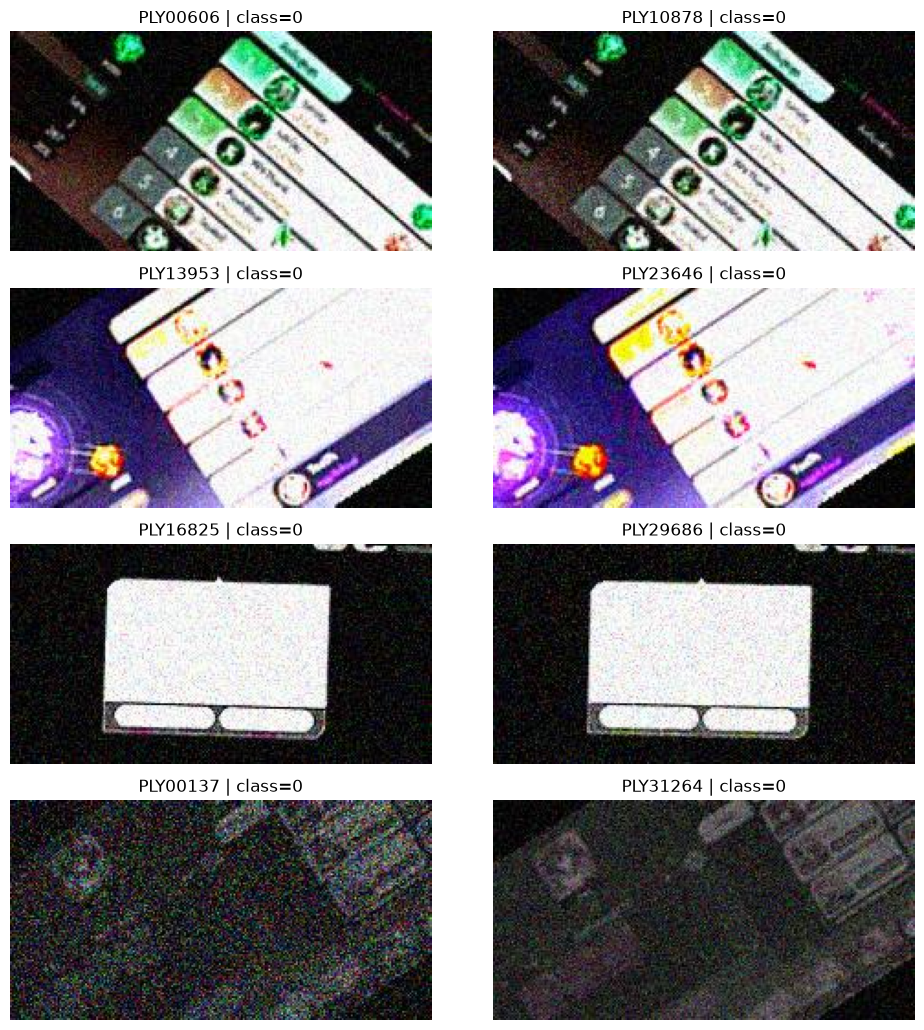

In [5]:
# Candidate pairs are conservative similarities, not proven original-source IDs.
import matplotlib.pyplot as plt
from PIL import Image
if len(near_pairs):
    sample_pairs = near_pairs.head(12)
    fig, axes = plt.subplots(len(sample_pairs), 2, figsize=(10, 2.6*len(sample_pairs)), squeeze=False)
    for row, pair in enumerate(sample_pairs.itertuples()):
        for column, index in enumerate([pair.row_a, pair.row_b]):
            item = groups.iloc[index]
            axes[row, column].imshow(Image.open(RAW / "train" / item.file_name))
            axes[row, column].set_title(f"{item.id} | class={int(item.label)}")
            axes[row, column].axis("off")
    fig.tight_layout()
    fig.savefig(AUDIT / "near_duplicate_review.png", dpi=120)
    plt.show()


## 4. Fixed Model Plan & Resume Settings

Full plan: source ResNet18 geometry fixed at seven epochs; longer cosine schedule; separate head/backbone learning rates; EfficientNet-B0; ConvNeXt-Tiny. All use the friend's aspect-preserving resize/padding, geometry augmentation and fold-local inverse-frequency class weights. Epoch counts are fixed before evaluation: **outer validation never selects a checkpoint**.

Each fitted model is checked with identity and a fixed five-view TTA (identity, ±8° rotation, 0.95/1.05 scale). Fixed soft ensembles average probabilities, not class labels. No OOF labels tune ensemble weights.

In [6]:
PROFILES = {
    "full": {"models": list(training.RECIPES), "folds": [1,2,3,4,5]},
    "balanced": {"models": ["friend_resnet18_fixed7", "resnet18_cosine18", "efficientnet_b0_cosine18"], "folds": [1,2,3]},
}
assert RUN_PROFILE in PROFILES and GROUP_MODE in ["exact", "near"]
active = PROFILES[RUN_PROFILE]
ENSEMBLES = {
    "resnet_effnet": ["resnet18_cosine18", "efficientnet_b0_cosine18"],
    "resnet_effnet_convnext": ["resnet18_cosine18", "efficientnet_b0_cosine18", "convnext_tiny_cosine18"],
}
plan = pd.DataFrame([{"model": name, **asdict(training.RECIPES[name])} for name in active["models"]])
display(plan)
from importlib.metadata import version
settings = {"run": RUN_NAME, "profile": RUN_PROFILE, "group_mode": GROUP_MODE,
    "recipes": {name: asdict(training.RECIPES[name]) for name in active["models"]},
    "folds": active["folds"], "batch_size": BATCH_SIZE, "workers": NUM_WORKERS,
    "tta_views": list(training.TTA_VIEWS), "ensembles": ENSEMBLES,
    "minimum_mean_gain": MIN_MEAN_GAIN, "fixed_epoch_selection": True,
    "audit_signature": json.loads((AUDIT / "audit_signature.json").read_text()),
    "fold_hash": hashlib.sha256(b"".join(valid.astype("int64").tobytes() for _,valid in folds)).hexdigest(),
    "helper_sha256": {name: hashlib.sha256(source.encode()).hexdigest() for name, source in bundled_files.items()},
    "versions": {name: version(name) for name in ["torch","torchvision","numpy","pandas","scikit-learn","Pillow"]},
}
OUT.mkdir(parents=True, exist_ok=True)
settings_path = OUT / "settings.json"
if settings_path.exists():
    assert json.loads(settings_path.read_text()) == settings, "Configuration changed: use a new RUN_NAME"
else:
    assert not any(OUT.iterdir()), "Nonempty output without settings"
    settings_path.write_text(json.dumps(settings, indent=2) + "\n")
plan.to_csv(OUT / "candidate_plan.csv", index=False)
assignment = pd.concat([pd.DataFrame({"row_index": valid, "id": groups.iloc[valid].id.to_numpy(),
                                      "fold": i}) for i,(_,valid) in enumerate(folds,1)],ignore_index=True)
assert assignment.row_index.is_unique and len(assignment) == len(groups)
assignment.to_parquet(OUT / "fold_assignments.parquet", index=False)
print("Fixed comparison ready:", len(active["models"])*len(active["folds"]), "fold fits")


,model,architecture,epochs,backbone_lr,head_lr,weight_decay,schedule,warmup_epochs,augmentation,label_smoothing,seed
0,friend_resnet18_fixed7,resnet18,7,0.00010,0.0001,0.0001,constant,0,geometry,0.0,42
1,resnet18_cosine18,resnet18,18,0.00010,0.0001,0.0001,cosine,2,geometry,0.0,42
2,resnet18_head_lr18,resnet18,18,0.00005,0.0005,0.0001,cosine,2,geometry,0.0,42
3,efficientnet_b0_cosine18,efficientnet_b0,18,0.00010,0.0003,0.0001,cosine,2,geometry,0.0,42
4,convnext_tiny_cosine18,convnext_tiny,18,0.00005,0.0003,0.0001,cosine,2,geometry,0.0,42


Fixed comparison ready: 25 fold fits


## 5. Train Fixed Recipes & Collect Soft OOF

In [7]:
# Resume is per completed epoch and per completed fold.
# Mid-epoch interruption repeats that epoch from its preceding saved state.
oof_by_model = {}
for name in active["models"]:
    parts = []
    for fold_number in active["folds"]:
        print("\nTraining:", name, "fold", fold_number, flush=True)
        frame = training.run_fold(RAW, groups, folds, name, fold_number, OUT,
                                  batch_size=BATCH_SIZE, workers=NUM_WORKERS)
        parts.append(frame)
        print("single:", training.score_probabilities(frame.true, training.probabilities(frame,"single")), flush=True)
        print("TTA:", training.score_probabilities(frame.true, training.probabilities(frame,"tta")), flush=True)
    oof_by_model[name] = pd.concat(parts, ignore_index=True).sort_values("row_index").reset_index(drop=True)
    assert oof_by_model[name].row_index.is_unique
    oof_by_model[name].to_parquet(OUT / f"{name}_oof.parquet", index=False)



Training: friend_resnet18_fixed7 fold 1
fold1 epoch 1 / 7 loss 0.52144 seconds 112.7
fold1 epoch 2 / 7 loss 0.26732 seconds 111.3
fold1 epoch 3 / 7 loss 0.20418 seconds 111.4
fold1 epoch 4 / 7 loss 0.16953 seconds 111.3
fold1 epoch 5 / 7 loss 0.14308 seconds 111.6
fold1 epoch 6 / 7 loss 0.1198 seconds 112.0
fold1 epoch 7 / 7 loss 0.10634 seconds 110.9
single: {'macro_F1': 0.9421634278117121, 'F1_7-11k': 0.9709762532981531, 'F1_fiveN': 0.9506378258458126, 'F1_freefried': 0.9342105263157895, 'F1_pube': 0.9281632653061225, 'F1_roblock': 0.926829268292683}
TTA: {'macro_F1': 0.9445702495498587, 'F1_7-11k': 0.9714517108726463, 'F1_fiveN': 0.9504730105731776, 'F1_freefried': 0.9424426766495086, 'F1_pube': 0.9365733113673805, 'F1_roblock': 0.9219105382865808}

Training: friend_resnet18_fixed7 fold 2
fold2 epoch 1 / 7 loss 0.51952 seconds 112.0
fold2 epoch 2 / 7 loss 0.27003 seconds 111.0
fold2 epoch 3 / 7 loss 0.20089 seconds 113.5
fold2 epoch 4 / 7 loss 0.16884 seconds 112.7
fold2 epoch 5 / 

100.0%


fold1 epoch 1 / 18 loss 0.80927 seconds 182.3
fold1 epoch 2 / 18 loss 0.37541 seconds 177.9
fold1 epoch 3 / 18 loss 0.24778 seconds 177.6
fold1 epoch 4 / 18 loss 0.18867 seconds 178.1
fold1 epoch 5 / 18 loss 0.15161 seconds 178.2
fold1 epoch 6 / 18 loss 0.12045 seconds 178.4
fold1 epoch 7 / 18 loss 0.09625 seconds 178.0
fold1 epoch 8 / 18 loss 0.08992 seconds 177.8
fold1 epoch 9 / 18 loss 0.07 seconds 177.9
fold1 epoch 10 / 18 loss 0.05955 seconds 178.1
fold1 epoch 11 / 18 loss 0.05101 seconds 177.8
fold1 epoch 12 / 18 loss 0.0473 seconds 177.7
fold1 epoch 13 / 18 loss 0.03737 seconds 177.6
fold1 epoch 14 / 18 loss 0.0354 seconds 177.8
fold1 epoch 15 / 18 loss 0.03065 seconds 177.7
fold1 epoch 16 / 18 loss 0.02988 seconds 177.8
fold1 epoch 17 / 18 loss 0.02689 seconds 177.7
fold1 epoch 18 / 18 loss 0.0264 seconds 177.6
single: {'macro_F1': 0.9785246893262167, 'F1_7-11k': 0.9869556492073048, 'F1_fiveN': 0.9784580498866213, 'F1_freefried': 0.9874439461883409, 'F1_pube': 0.981756470089096

KeyboardInterrupt: 

In [7]:
print("โมเดลที่พร้อมประเมิน:")
for name, frame in oof_by_model.items():
    print(name, "| folds:", sorted(frame["fold"].unique()))

โมเดลที่พร้อมประเมิน:


NameError: name 'oof_by_model' is not defined

In [8]:
completed_models = [
    "friend_resnet18_fixed7",
    "resnet18_cosine18",
    "resnet18_head_lr18",
]

oof_by_model = {
    name: pd.read_parquet(OUT / f"{name}_oof.parquet")
    for name in completed_models
}

## 6. Single View, TTA & Fixed Ensembles

In [9]:
aligned = next(iter(oof_by_model.values()))
procedure_probabilities, procedure_members = {}, {}
for name, frame in oof_by_model.items():
    assert np.array_equal(frame.row_index, aligned.row_index)
    assert np.array_equal(frame.id, aligned.id) and np.array_equal(frame.true, aligned.true)
    for mode in ["single","tta"]:
        key = name + "__" + mode
        procedure_probabilities[key] = training.probabilities(frame, mode)
        procedure_members[key] = {"models":[name], "mode":mode}
for label, members in ENSEMBLES.items():
    if set(members).issubset(oof_by_model):
        for mode in ["single","tta"]:
            key = "ensemble_" + label + "__" + mode
            procedure_probabilities[key] = np.mean([training.probabilities(oof_by_model[m],mode) for m in members],axis=0)
            procedure_members[key] = {"models":members, "mode":mode}
rows = []
for name, probability in procedure_probabilities.items():
    for fold_number in active["folds"]:
        mask = aligned.fold.eq(fold_number).to_numpy()
        rows.append({"procedure":name,"fold":fold_number,
                     **training.score_probabilities(aligned.loc[mask,"true"],probability[mask])})
fold_scores = pd.DataFrame(rows)
BASELINE = "friend_resnet18_fixed7__single"
paired = fold_scores.pivot(index="fold",columns="procedure",values="macro_F1")
ranking = pd.DataFrame({"mean_macro_F1":paired.mean(),"std_macro_F1":paired.std(),
    "delta_vs_paired_baseline":paired.sub(paired[BASELINE],axis=0).mean(),
    "folds_better":paired.gt(paired[BASELINE],axis=0).sum(),
    "folds_worse":paired.lt(paired[BASELINE],axis=0).sum()}).sort_values("mean_macro_F1",ascending=False).reset_index()
fold_scores.to_csv(OUT / "fold_scores.csv",index=False)
ranking.to_csv(OUT / "model_ranking.csv",index=False)
display(ranking.round(6))
display(paired.round(5))
minimum_wins = int(np.ceil(.75*len(active["folds"])))
eligible = ranking.loc[ranking.delta_vs_paired_baseline.ge(MIN_MEAN_GAIN)&ranking.folds_better.ge(minimum_wins)]
SELECTED = eligible.iloc[0].procedure if len(eligible) else BASELINE
selected_procedure = procedure_members[SELECTED]
print("Selected:",SELECTED)
(OUT / "selection.json").write_text(json.dumps({"selected":SELECTED,"members":selected_procedure,
    "minimum_mean_gain":MIN_MEAN_GAIN,"minimum_wins":minimum_wins,
    "note":"Exploratory choice on reused OOF; no official Kaggle score or untouched estimate"},indent=2))


,procedure,mean_macro_F1,std_macro_F1,delta_vs_paired_baseline,folds_better,folds_worse
0,resnet18_cosine18__tta,0.975511,0.001516,0.029320,5,0
1,resnet18_cosine18__single,0.973691,0.001511,0.027500,5,0
2,resnet18_head_lr18__tta,0.972428,0.001379,0.026237,5,0
3,resnet18_head_lr18__single,0.970248,0.002073,0.024058,5,0
4,friend_resnet18_fixed7__tta,0.948966,0.005024,0.002776,5,0
5,friend_resnet18_fixed7__single,0.946191,0.004453,0.000000,0,0


procedure,friend_resnet18_fixed7__single,friend_resnet18_fixed7__tta,resnet18_cosine18__single,resnet18_cosine18__tta,resnet18_head_lr18__single,resnet18_head_lr18__tta
fold,,,,,,
1,0.94216,0.94457,0.97287,0.97370,0.97313,0.97384
2,0.94183,0.94578,0.97469,0.97788,0.97175,0.97341
3,0.95086,0.95615,0.97162,0.97528,0.96882,0.97117
4,0.94528,0.94602,0.97547,0.97502,0.96841,0.97296
5,0.95083,0.95230,0.97381,0.97567,0.96914,0.97076


Selected: resnet18_cosine18__tta


274

## 7. Error Analysis — Classes, Confidence, Image Quality

              precision    recall  f1-score   support

       7-11k       0.98      0.99      0.99     12429
       fiveN       0.98      0.97      0.97      4407
   freefried       0.98      0.98      0.98      5596
        pube       0.98      0.97      0.98      5926
     roblock       0.96      0.96      0.96      3188

    accuracy                           0.98     31546
   macro avg       0.98      0.97      0.98     31546
weighted avg       0.98      0.98      0.98     31546



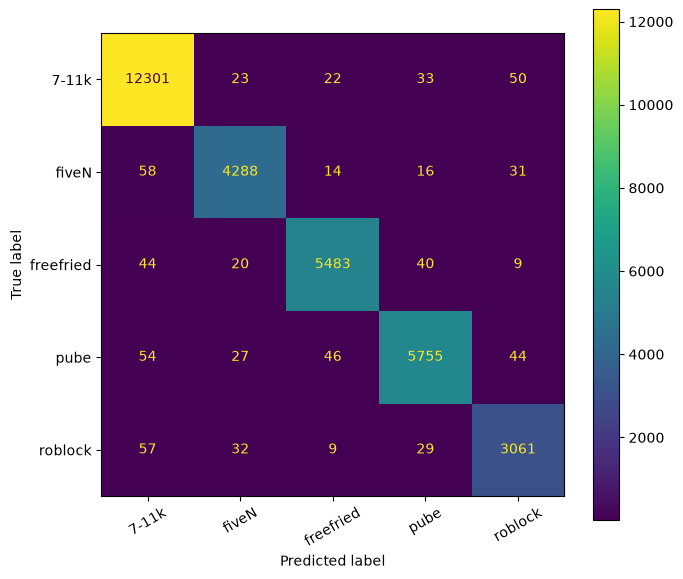

,feature,band,rows,error_rate,mean_confidence
0,brightness,"(3.7920000000000003, 72.514]",7887,0.028528,0.976580
1,brightness,"(72.514, 113.564]",7886,0.012808,0.988086
2,brightness,"(113.564, 155.633]",7886,0.015724,0.988050
3,brightness,"(155.633, 246.38]",7887,0.026373,0.981433
4,contrast,"(0.731, 30.963]",7887,0.032332,0.973931
5,contrast,"(30.963, 48.441]",7886,0.017246,0.986570
6,contrast,"(48.441, 63.942]",7886,0.017880,0.985964
7,contrast,"(63.942, 114.584]",7887,0.015976,0.987684
8,edge_energy,"(0.689, 10.675]",7887,0.039812,0.969498
9,edge_energy,"(10.675, 16.592]",7887,0.018765,0.985144


In [10]:
selected_prob = procedure_probabilities[SELECTED]
selected_oof = aligned[["row_index","id","true","fold"]].copy()
selected_oof["pred"] = selected_prob.argmax(axis=1)
selected_oof["confidence"] = selected_prob.max(axis=1)
for label in range(5):selected_oof[f"p_{label}"] = selected_prob[:,label]
selected_oof["correct"] = selected_oof.pred.eq(selected_oof.true)
selected_oof.to_parquet(OUT / "selected_oof.parquet",index=False)
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
print(classification_report(selected_oof.true,selected_oof.pred,labels=range(5),target_names=training.CLASS_NAMES,zero_division=0))
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(selected_oof.true,selected_oof.pred,labels=range(5),display_labels=training.CLASS_NAMES,ax=ax,xticks_rotation=30)
fig.tight_layout();fig.savefig(OUT / "confusion_matrix.png",dpi=130);plt.show()
quality = metadata.loc[metadata.split.eq("train"),["id","file_name","brightness","contrast","edge_energy"]]
error_audit = selected_oof.merge(quality,on="id",validate="one_to_one")
quality_slices=[]
for field in ["brightness","contrast","edge_energy"]:
    band=pd.qcut(error_audit[field],4,duplicates="drop")
    for interval,index in error_audit.groupby(band,observed=True).groups.items():
        part=error_audit.loc[index]
        quality_slices.append({"feature":field,"band":str(interval),"rows":len(part),
                               "error_rate":1-part.correct.mean(),"mean_confidence":part.confidence.mean()})
pd.DataFrame(quality_slices).to_csv(OUT / "image_quality_error_slices.csv",index=False)
error_audit.to_parquet(OUT / "error_audit.parquet",index=False)
display(pd.DataFrame(quality_slices))


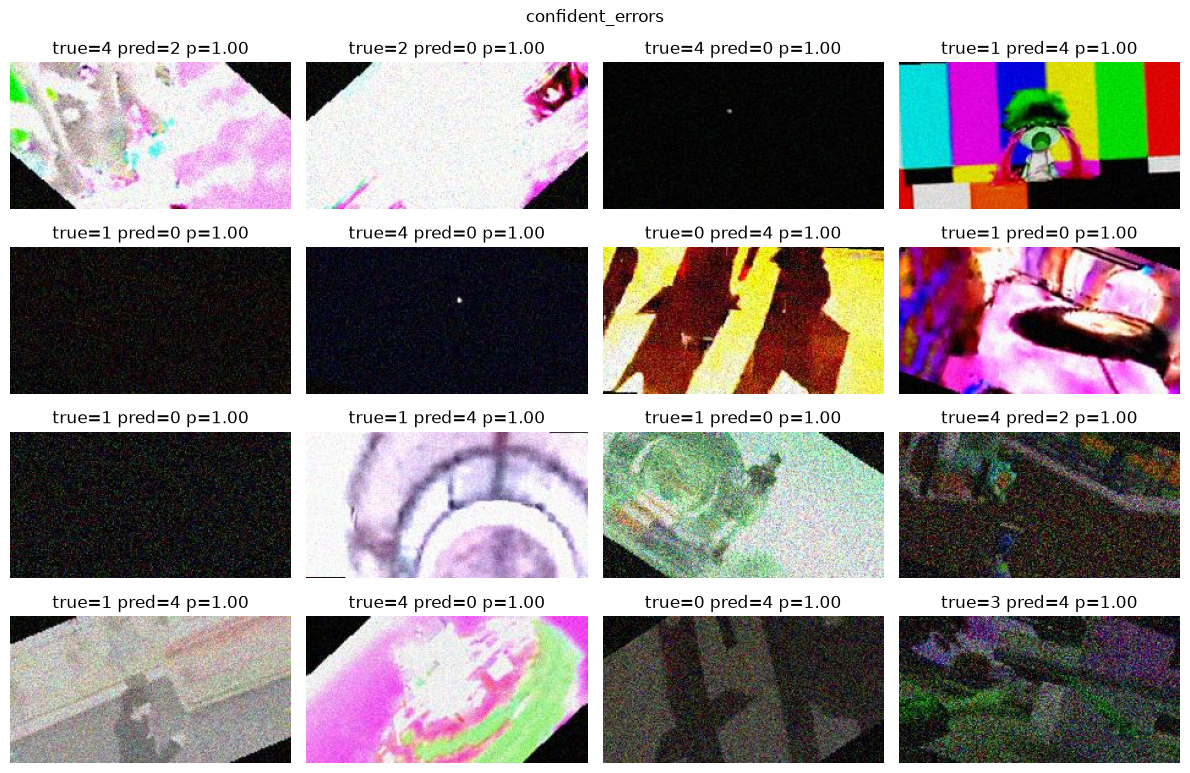

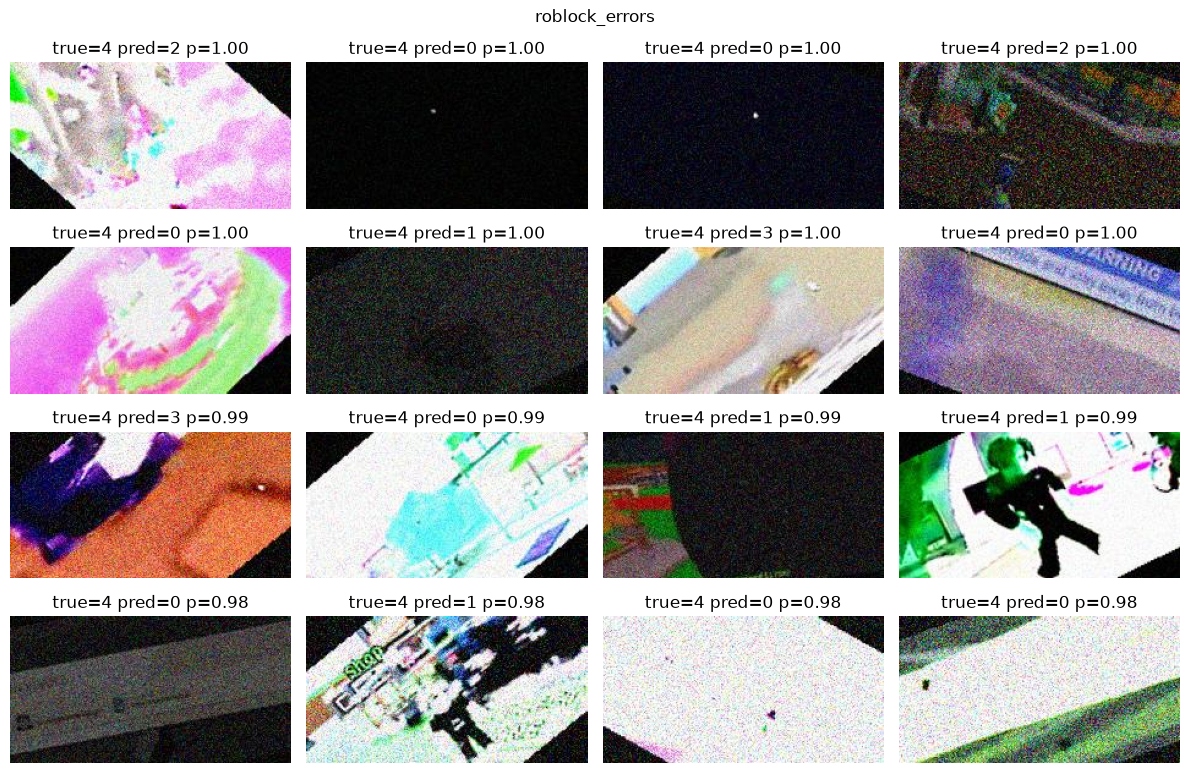

In [11]:
# Inspect confident mistakes and the weakest-class mistakes, not just accuracy.
for title, subset in [
    ("confident_errors",error_audit.loc[~error_audit.correct].sort_values("confidence",ascending=False).head(16)),
    ("roblock_errors",error_audit.loc[(~error_audit.correct)&error_audit.true.eq(4)].sort_values("confidence",ascending=False).head(16))]:
    if subset.empty:continue
    fig,axes=plt.subplots(4,4,figsize=(12,8))
    for ax in axes.flat:ax.axis("off")
    for ax,row in zip(axes.flat,subset.itertuples()):
        ax.imshow(Image.open(RAW / "train" / row.file_name))
        ax.set_title(f"true={row.true} pred={row.pred} p={row.confidence:.2f}")
    fig.suptitle(title);fig.tight_layout();fig.savefig(OUT / f"{title}.png",dpi=130);plt.show()


## 8. Refit Selected Procedure on All Train Images

Fit only the selected member models with exactly the fixed recipe, preprocessing and epoch schedule evaluated above. Full-data weights do not receive a new validation score. If an ensemble wins, each member is refitted independently; checkpoint loading for inference never downloads pretrained weights.

In [11]:
full_paths = {}
if RUN_FULL_REFIT:
    for name in selected_procedure["models"]:
        full_paths[name] = training.fit_fixed(RAW,groups,training.RECIPES[name],OUT / name / "full",
            batch_size=BATCH_SIZE,workers=NUM_WORKERS)
    print("Full models:",full_paths)
else:
    print("Full refit disabled; results/OOF remain available")


full epoch 1 / 18 loss 0.52914 seconds 139.9
full epoch 2 / 18 loss 0.30208 seconds 138.4
full epoch 3 / 18 loss 0.20901 seconds 138.2
full epoch 4 / 18 loss 0.16872 seconds 138.6
full epoch 5 / 18 loss 0.13788 seconds 140.3
full epoch 6 / 18 loss 0.11586 seconds 141.4
full epoch 7 / 18 loss 0.09915 seconds 140.9
full epoch 8 / 18 loss 0.08057 seconds 144.5
full epoch 9 / 18 loss 0.07222 seconds 141.8
full epoch 10 / 18 loss 0.05516 seconds 142.2
full epoch 11 / 18 loss 0.04702 seconds 142.2
full epoch 12 / 18 loss 0.03513 seconds 142.0
full epoch 13 / 18 loss 0.02662 seconds 142.6
full epoch 14 / 18 loss 0.02076 seconds 142.5
full epoch 15 / 18 loss 0.01863 seconds 142.7
full epoch 16 / 18 loss 0.0146 seconds 145.5
full epoch 17 / 18 loss 0.01235 seconds 144.1
full epoch 18 / 18 loss 0.01192 seconds 142.5
Full models: {'resnet18_cosine18': PosixPath('/Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/gpu_followup_v1/resnet18_cosine18/full/model.pt')

## 9. Predict Current Test Manifest & Export Task 4

In [12]:
if RUN_FULL_REFIT:
    test = pd.read_csv(RAW / "test.csv")
    assert test.columns.tolist()==["id","file_name","label"]
    assert len(test)==25889 and test.id.is_unique and test.label.isna().all()
    mode = selected_procedure["mode"]
    views = training.TTA_VIEWS if mode=="tta" else ("identity",)
    member_probabilities=[]
    for name,path in full_paths.items():
        cache=OUT / f"{name}_test_{mode}_probabilities.parquet"
        if cache.exists():
            saved=pd.read_parquet(cache)
            assert saved.id.tolist()==test.id.tolist()
            probability=saved[[f"p_{c}" for c in range(5)]].to_numpy()
        else:
            model=training.load_model(path)
            view_probs=training.predict_views(model,RAW,test,"test",BATCH_SIZE,NUM_WORKERS,views)
            probability=np.mean(list(view_probs.values()),axis=0)
            saved=pd.DataFrame(probability,columns=[f"p_{c}" for c in range(5)])
            saved.insert(0,"id",test.id.to_numpy());saved.to_parquet(cache,index=False)
            del model
            if training.get_device().type=="cuda":torch.cuda.empty_cache()
        assert np.isfinite(probability).all() and np.allclose(probability.sum(axis=1),1,atol=1e-5)
        member_probabilities.append(probability)
    final_probability=np.mean(member_probabilities,axis=0)
    predictions=pd.DataFrame({"id":test.id.to_numpy(),"task4":final_probability.argmax(axis=1)})
    assert predictions.id.tolist()==test.id.tolist() and predictions.task4.isin(range(5)).all()
    predictions.to_csv(OUT / "task4_predictions.csv",index=False)
    probability_output=pd.DataFrame(final_probability,columns=[f"p_{c}" for c in range(5)])
    probability_output.insert(0,"id",test.id.to_numpy());probability_output.to_parquet(OUT / "test_probabilities.parquet",index=False)
    model_card={"procedure":SELECTED,"members":selected_procedure,"classes":list(training.CLASS_NAMES),
        "train_rows":len(groups),"test_rows":len(test),
        "test_manifest_sha256":hashlib.sha256((RAW / "test.csv").read_bytes()).hexdigest(),
        "settings_sha256":hashlib.sha256(settings_path.read_bytes()).hexdigest(),
        "cv_mean_macro_F1":float(ranking.loc[ranking.procedure.eq(SELECTED),"mean_macro_F1"].item()),
        "score_note":"Selected procedure on explored OOF; not a full-fit score or official Kaggle result",
        "kaggle_submitted":False}
    (OUT / "selected_model_card.json").write_text(json.dumps(model_card,indent=2)+"\n")
    display(predictions.head());display(predictions.task4.value_counts().sort_index())
    print("Ready:",OUT / "task4_predictions.csv")


,id,task4
0,ANS00001,0
1,ANS00002,2
2,ANS00003,3
3,ANS00004,0
4,ANS00005,3


task4
0    5017
1    5579
2    3764
3    7247
4    4282
Name: count, dtype: int64

Ready: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/gpu_followup_v1/task4_predictions.csv


## 10. Run Notes

Keep `settings.json`, `candidate_plan.csv`, OOF, paired fold scores, `selection.json`, error grids, full model checkpoints and Test probability files together. Resume by running the same settings and persistent output directory; changing recipes, batch size, software versions or group mode requires a new run name. An interrupted epoch restarts from the prior completed epoch. Different GPU/software environments can still change numerical results.

Near-duplicate grouping is conservative and incomplete. Four candidate pairs were found during the local audit; zero exact Train/Test overlaps were found. This audit does not establish every original screenshot source. The seven-epoch baseline and near groups differ from the friend's reported epoch-selected 0.95447 procedure, so judge gains against the newly fitted paired baseline.

## 11. Save pretrained models for future transfer learning

In [13]:
# 11. Save pretrained models for future transfer learning

from pathlib import Path
import json
import hashlib
import torch

if "full_paths" not in globals() or not full_paths:
    raise RuntimeError("กรุณารันส่วน 8 ให้ฝึกโมเดลสุดท้ายเสร็จก่อน")

EXPORT_DIR = Path(OUT) / "transfer_learning"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

exported = []

for name, checkpoint_path in full_paths.items():
    checkpoint_path = Path(checkpoint_path)

    # โหลด weights ลง CPU เพื่อให้ย้ายไปใช้เครื่องอื่นได้
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    package = {
        "format_version": 1,
        "model_name": name,
        "architecture": checkpoint["identity"]["recipe"]["architecture"],
        "class_names": checkpoint["class_names"],
        "state_dict": {
            key: value.detach().cpu()
            for key, value in checkpoint["state_dict"].items()
        },
        "preprocessing": {
            "color_mode": "RGB",
            "resize_hw": [112, 224],
            "padding_ltrb": [0, 56, 0, 56],
            "mean": [0.485, 0.456, 0.406],
            "std": [0.229, 0.224, 0.225],
        },
        "training_recipe": checkpoint["identity"]["recipe"],
    }

    save_path = EXPORT_DIR / f"{name}_pretrained.pt"
    temporary_path = save_path.with_suffix(".partial.pt")

    # เขียนไฟล์ให้ครบก่อนเปลี่ยนเป็นชื่อไฟล์จริง
    torch.save(package, temporary_path)
    temporary_path.replace(save_path)

    # โหลดไฟล์ที่เขียนแล้วกลับมาตรวจ weights ทุกตัว
    restored = torch.load(
        save_path,
        map_location="cpu",
        weights_only=True,
    )

    assert restored["architecture"] == package["architecture"]
    assert restored["state_dict"].keys() == package["state_dict"].keys()
    assert all(
        torch.equal(value, restored["state_dict"][key])
        for key, value in package["state_dict"].items()
    )

    size_mb = save_path.stat().st_size / (1024 ** 2)

    exported.append({
        "model": name,
        "architecture": package["architecture"],
        "file": save_path.name,
        "size_mb": round(size_mb, 2),
        "sha256": hashlib.sha256(save_path.read_bytes()).hexdigest(),
    })

    print(f"Saved: {save_path.resolve()}")
    print(f"Size: {size_mb:.2f} MB | โหลดกลับและตรวจ weights ผ่านแล้ว\n")

    del checkpoint, package, restored

# เก็บรายการไฟล์และวิธีรวมผลของโมเดลที่เลือก
selection_path = Path(OUT) / "selection.json"

manifest = {
    "models": exported,
    "original_selection": (
        json.loads(selection_path.read_text())
        if selection_path.exists() else None
    ),
}

(EXPORT_DIR / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("บันทึกเสร็จทั้งหมดที่:", EXPORT_DIR.resolve())

Saved: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/gpu_followup_v1/transfer_learning/resnet18_cosine18_pretrained.pt
Size: 42.72 MB | โหลดกลับและตรวจ weights ผ่านแล้ว

บันทึกเสร็จทั้งหมดที่: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/gpu_followup_v1/transfer_learning
